In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import genextreme

os.makedirs("figuras", exist_ok=True)
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [9]:
point = "p102"

hs_sims = pd.read_pickle(f"outputs/ruido/olas_hindcast_{point}.pkl")['VHM0']  
tp_sims = pd.read_pickle(f"outputs/ruido/olas_hindcast_{point}.pkl")['VTM02'] 
            # (horas, realizaciones)
hs_all = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"].loc["1985":"2025"]
tp_all = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VTM02"].loc["1985":"2025"]

hs_all = hs_all.reindex(hs_sims.index)
tp_all = tp_all.reindex(tp_sims.index)

hs_sims = hs_sims.where(hs_all.notna(), axis=0)                                    # mismas horas que el observado
print(hs_sims.shape, f"{hs_all.notna().mean():.1%} de horas con observación")

tp_sims = tp_sims.where(tp_all.notna(), axis=0)                                    # mismas horas que el observado
print(tp_sims.shape, f"{tp_all.notna().mean():.1%} de horas con observación")

(359400, 50) 100.0% de horas con observación
(359400, 50) 100.0% de horas con observación


años con el máximo observado dentro del 95 % simulado: 95%  (esperado ≈ 95 %)
por encima: 0% | por debajo: 5%
media máx. anual: obs 5.66 | sim 5.72 [5.57–5.88]
corr año a año (obs vs mediana sim): 0.52


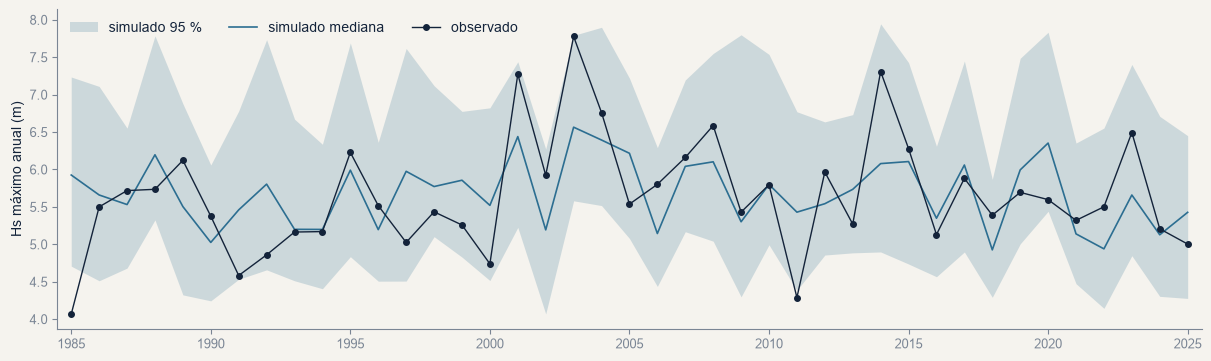

In [10]:
#### Máximos anuales
am_obs = hs_all.groupby(hs_all.index.year).max()
am_sim = hs_sims.groupby(hs_sims.index.year).max()            # (41 años, n_sims)
lo, med, hi = am_sim.quantile(0.025, axis=1), am_sim.median(axis=1), am_sim.quantile(0.975, axis=1)

dentro = ((am_obs >= lo) & (am_obs <= hi)).mean()
print(f"años con el máximo observado dentro del 95 % simulado: {dentro:.0%}  (esperado ≈ 95 %)")
print(f"por encima: {(am_obs > hi).mean():.0%} | por debajo: {(am_obs < lo).mean():.0%}")
print(f"media máx. anual: obs {am_obs.mean():.2f} | sim {am_sim.mean().median():.2f} [{am_sim.mean().quantile(0.025):.2f}–{am_sim.mean().quantile(0.975):.2f}]")
print(f"corr año a año (obs vs mediana sim): {am_obs.corr(med):.2f}")

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(am_sim.index, lo, hi, color=AZUL, alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(med, color=AZUL, lw=1.2, label="simulado mediana")
ax.plot(am_obs, "o-", color=TINTA, ms=4, lw=1, label="observado")
ax.set(ylabel="Hs máximo anual (m)", xlim=(am_obs.index[0] - 0.5, am_obs.index[-1] + 0.5))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=3)
fig.savefig("figuras/extremos_maximos_anuales.png", dpi=200)
plt.show()

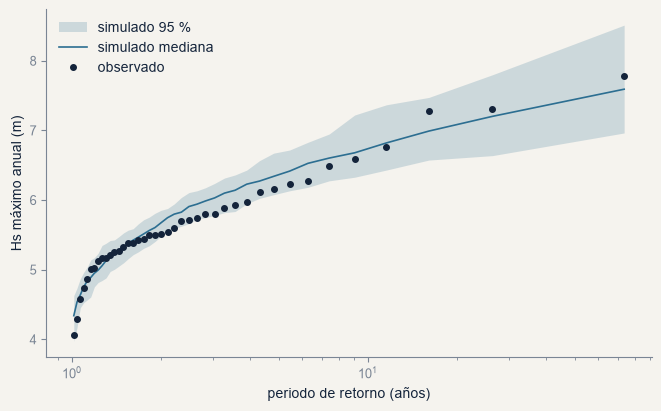

In [11]:
#### Curva de periodos de retorno empírica (Gringorten): obs vs banda de las simulaciones
n = len(am_obs)
T = 1 / (1 - (np.arange(1, n + 1) - 0.44) / (n + 0.12))           # periodo de retorno de cada orden
am_sim_ord = np.sort(am_sim.values, axis=0)                       # (n, n_sims), cada simulación ordenada

fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
ax.fill_between(T, np.percentile(am_sim_ord, 2.5, axis=1), np.percentile(am_sim_ord, 97.5, axis=1),
                color=AZUL, alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(T, np.median(am_sim_ord, axis=1), color=AZUL, lw=1.2, label="simulado mediana")
ax.plot(T, np.sort(am_obs.values), "o", color=TINTA, ms=4, label="observado")
ax.set(xscale="log", xlabel="periodo de retorno (años)", ylabel="Hs máximo anual (m)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.savefig("figuras/extremos_gringorten.png", dpi=200)
plt.show()

In [12]:
#### GEV: parámetros y niveles de retorno, obs vs simulaciones
T_ret = np.array([2, 10, 50, 100])

def gev(am):
    c_, loc, scale = genextreme.fit(am)
    return {"ξ": -c_, "μ": loc, "σ": scale, **{f"Hs{t}": genextreme.ppf(1 - 1 / t, c_, loc, scale) for t in T_ret}}

g_obs = pd.Series(gev(am_obs.values))
g_sim = pd.DataFrame([gev(am_sim[c_].values) for c_ in am_sim.columns])
tabla_gev = pd.DataFrame({"obs": g_obs, "sim med": g_sim.median(), "sim lo": g_sim.quantile(0.025), "sim hi": g_sim.quantile(0.975)})
print(tabla_gev.round(2).to_string())
print("ojo: con 41 años, ξ y Hs100 tienen mucha incertidumbre también en lo observado")

        obs  sim med  sim lo  sim hi
ξ     -0.13    -0.14   -0.38    0.08
μ      5.34     5.41    5.25    5.58
σ      0.68     0.67    0.58    0.84
Hs2    5.59     5.65    5.48    5.83
Hs10   6.67     6.72    6.50    6.99
Hs50   7.43     7.49    6.91    8.23
Hs100  7.70     7.77    7.02    8.84
ojo: con 41 años, ξ y Hs100 tienen mucha incertidumbre también en lo observado


Spearman Hs–Tm02: obs 0.809 | sim p50 0.822 [0.819–0.824]
u        0.800  0.900  0.950  0.980  0.990  0.995  0.998
obs      0.637  0.534  0.459  0.379  0.310  0.257  0.226
sim p5   0.697  0.602  0.527  0.442  0.375  0.300  0.229
sim p50  0.702  0.612  0.543  0.465  0.409  0.355  0.275
sim p95  0.707  0.619  0.553  0.481  0.431  0.383  0.331
Tm02 con Hs > U99 (q10/q50/q90): obs [6.17 6.69 7.28] | sim p50 [5.54 6.72 7.59] | p5 [5.44 6.66 7.53] | p95 [5.66 6.77 7.68]


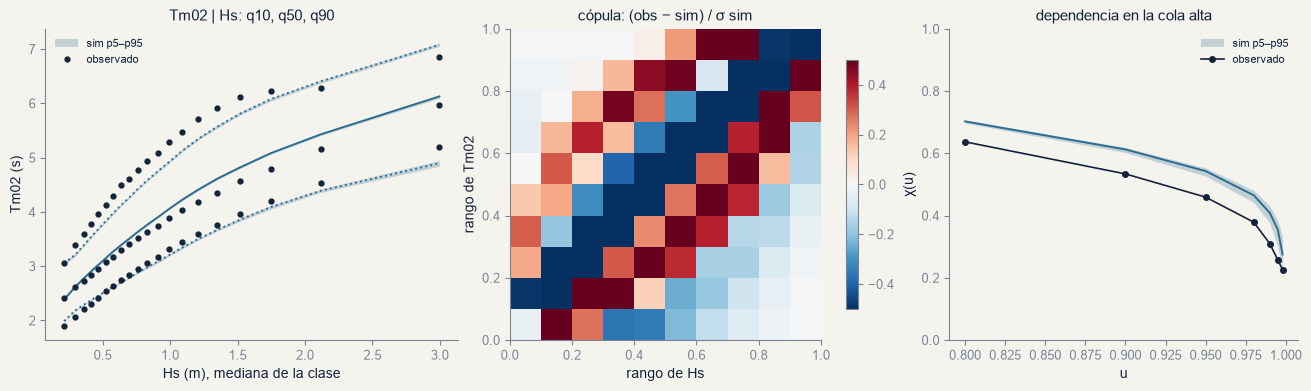

In [16]:
#### Cópula Hs–Tm02 (hindcast): régimen medio y extremal, en rangos (sin efecto de las marginales)
tp_sims = tp_sims.where(tp_all.notna(), axis=0)                         # mismas horas que el observado también para Tm02
ok = hs_all.notna() & tp_all.notna()
n_ok = ok.sum()
U_obs, V_obs = hs_all[ok].rank() / (n_ok + 1), tp_all[ok].rank() / (n_ok + 1)
U_sim, V_sim = hs_sims[ok].rank() / (n_ok + 1), tp_sims[ok].rank() / (n_ok + 1)   # rangos por realización

#### 1. Régimen medio: Spearman y Tm02 condicionado a Hs (20 clases por cuantiles de Hs observada)
rho_sim = U_sim.corrwith(V_sim)
print(f"Spearman Hs–Tm02: obs {U_obs.corr(V_obs):.3f} | sim p50 {rho_sim.median():.3f} [{rho_sim.quantile(0.05):.3f}–{rho_sim.quantile(0.95):.3f}]")

bordes_h = hs_all[ok].quantile(np.linspace(0, 1, 21)).values[1:-1]
centros_h = hs_all[ok].groupby(np.digitize(hs_all[ok], bordes_h)).median().values
cond = lambda h, t: t.groupby(np.digitize(h, bordes_h)).quantile([0.1, 0.5, 0.9]).unstack()   # (clase, q)
c_obs = cond(hs_all[ok], tp_all[ok])
c_sim = np.stack([cond(hs_sims.loc[ok, c], tp_sims.loc[ok, c]).values for c in hs_sims.columns])   # (sim, clase, q)

#### 2. Densidad de la cópula 10 × 10: (obs − media sim) / σ entre simulaciones
dens = lambda U, V: np.histogram2d(U, V, bins=10, range=[[0, 1], [0, 1]])[0] / len(U) * 100
d_obs = dens(U_obs.values, V_obs.values)
d_sim = np.stack([dens(U_sim[c].values, V_sim[c].values) for c in U_sim.columns])
z_dens = d_obs - d_sim.mean(0)                     # puntos porcentuales de masa (cada celda vale 1 % en la independencia)

#### 3. Extremal: χ(u) = P(V > u | U > u) y Tm02 con Hs > U99
us = np.array([0.80, 0.90, 0.95, 0.98, 0.99, 0.995, 0.998])
chi = lambda U, V: np.array([((U > u) & (V > u)).sum() / (U > u).sum() for u in us])
chi_obs = chi(U_obs.values, V_obs.values)
chi_sim = np.array([chi(U_sim[c].values, V_sim[c].values) for c in U_sim.columns])
print(pd.DataFrame({"obs": chi_obs, "sim p5": np.percentile(chi_sim, 5, 0), "sim p50": np.median(chi_sim, 0),
                    "sim p95": np.percentile(chi_sim, 95, 0)}, index=pd.Index(us, name="u")).round(3).T)

U99 = hs_all.quantile(0.99)
q_ext = lambda h, t: t[h > U99].quantile([0.1, 0.5, 0.9]).values
e_sim = np.array([q_ext(hs_sims.loc[ok, c], tp_sims.loc[ok, c]) for c in hs_sims.columns])
print(f"Tm02 con Hs > U99 (q10/q50/q90): obs {np.round(q_ext(hs_all[ok], tp_all[ok]), 2)} | "
      f"sim p50 {np.round(np.median(e_sim, 0), 2)} | p5 {np.round(np.percentile(e_sim, 5, 0), 2)} | p95 {np.round(np.percentile(e_sim, 95, 0), 2)}")

#### Figura
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True, gridspec_kw={"width_ratios": [1.3, 1, 1.1]})
for j, (q, ls) in enumerate([(0.1, ":"), (0.5, "-"), (0.9, ":")]):
    p5, p50, p95 = np.percentile(c_sim[:, :, j], [5, 50, 95], axis=0)
    axs[0].fill_between(centros_h, p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim p5–p95" if j == 1 else None)
    axs[0].plot(centros_h, p50, color=AZUL, lw=1.4, ls=ls)
    axs[0].plot(centros_h, c_obs[q].values, "o", color=TINTA, ms=3.5, label="observado" if j == 1 else None)
axs[0].set(xlabel="Hs (m), mediana de la clase", ylabel="Tm02 (s)", title="Tm02 | Hs: q10, q50, q90")
axs[0].legend(frameon=False, fontsize=8)

im = axs[1].imshow(z_dens.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axs[1].set(xlabel="rango de Hs", ylabel="rango de Tm02", title="cópula: (obs − sim) / σ sim")
fig.colorbar(im, ax=axs[1], shrink=0.8)

axs[2].fill_between(us, np.percentile(chi_sim, 5, 0), np.percentile(chi_sim, 95, 0), color=AZUL, alpha=0.25, lw=0, label="sim p5–p95")
axs[2].plot(us, np.median(chi_sim, 0), color=AZUL, lw=1.4)
axs[2].plot(us, chi_obs, "o-", color=TINTA, ms=4, lw=1.2, label="observado")
axs[2].set(xlabel="u", ylabel="χ(u)", title="dependencia en la cola alta", ylim=(0, 1))
axs[2].legend(frameon=False, fontsize=8)
fig.savefig("figuras/06B_copula_hs_tm02.png", dpi=200)
plt.show()